<a href="https://colab.research.google.com/github/Xskyis/Pembelajaran-Mesin-2026/blob/main/TG9_Klasifikasi_244107020001.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Praktikum 1**

Langah 1 - Load Data



In [3]:
	# Load data
	import pandas as pd
	data = pd.read_csv('Iris.csv')
	data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Langkah 2 - Eksplorasi Data


In [4]:
	data.info()
	data.describe()
	data['species'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count
species,
setosa,50
versicolor,50
virginica,50


Langkah 3 - Visualisasi Data



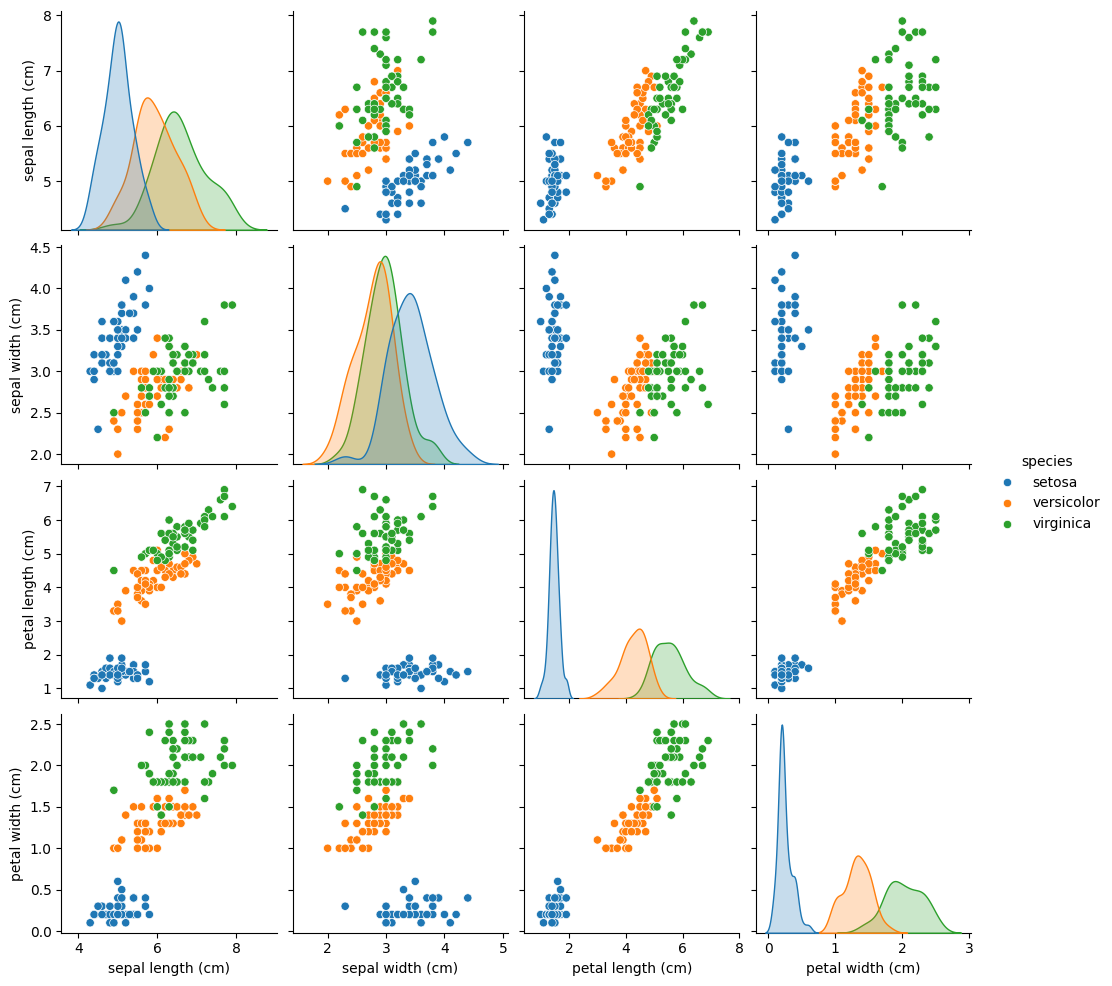

In [5]:
	import seaborn as sns
	import matplotlib.pyplot as plt

	sns.pairplot(data, hue='species')
	plt.show()

Langkah 4 - Preprocessing


In [6]:
	from sklearn.model_selection import train_test_split
	from sklearn.preprocessing import StandardScaler

	X = data.iloc[:, :-1]   # semua kolom kecuali label
	y = data.iloc[:, -1]    # kolom label terakhir

	# Split data (70% train, 30% test)
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

	# Standardisasi
	scaler = StandardScaler()
	X_train = scaler.fit_transform(X_train)
	X_test = scaler.transform(X_test)

Langkah 5 - Buat Model kNN



In [7]:
	from sklearn.neighbors import KNeighborsClassifier

	# Tentukan nilai K (misalnya 3)
	knn = KNeighborsClassifier(n_neighbors=3)

	# Latih model
	knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

Langkah 6 - Evaluasi Model kNN


In [8]:
	from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

	y_pred = knn.predict(X_test)
	print("Akurasi:", accuracy_score(y_test, y_pred))
	print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
	print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



mengevaluasi setiap nilai
k
k.

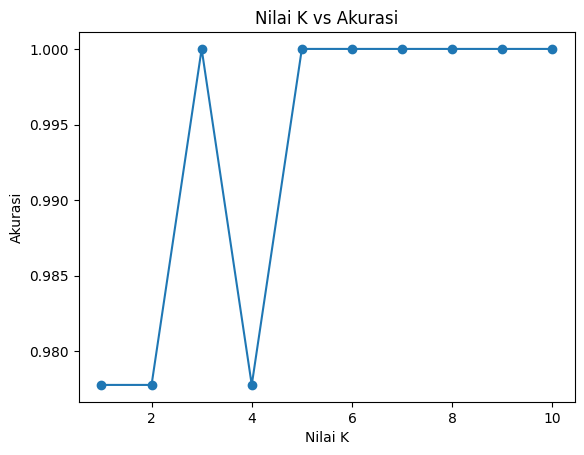

In [9]:
	acc = []
	for k in range(1, 11):
	    model = KNeighborsClassifier(n_neighbors=k)
	    model.fit(X_train, y_train)
	    acc.append(model.score(X_test, y_test))

	plt.plot(range(1, 11), acc, marker='o')
	plt.title('Nilai K vs Akurasi')
	plt.xlabel('Nilai K')
	plt.ylabel('Akurasi')
	plt.show()


# **Praktikum 2**

**Klasifikasi Naive Bayes dengan Data Dummy**

Langkah 1 - Buat Dataset Dummy



In [10]:
	import numpy as np
	from sklearn.datasets import make_classification

	# Membuat data dummy
	# Hasil dari make_classification berupa data fitur X dan label y
	# Label y akan berupa data yang sudah di encode (angka)
	X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

	# Secara defalt, make_classfication menghasilkan nilai float
	# Kita perlu merubah dalam bentuk diskrit

	# Absolutekan nilai
	X = np.absolute(X)

	# Bulatkan nilai ke 2 angka dibelakang koma
	# Kalikan dengan 100 supaya tidak ada lagi koma
	X = np.round(X, 2) * 100

	# Ubah ke dalam bentuk integer
	X = X.astype(int)

	# Cek Hasil
	print(X)
	print(y)

[[198  11]
 [150  44]
 [316 129]
 [106  94]
 [ 62 285]
 [127  70]
 [165  16]
 [107  87]
 [ 45  47]
 [136 162]
 [166 110]
 [206  32]
 [ 96 146]
 [107 148]
 [ 44 190]
 [  9  85]
 [138 134]
 [ 64  35]
 [ 32   6]
 [ 80  78]
 [181 142]
 [126 144]
 [196 200]
 [ 39 217]
 [ 93 202]
 [ 13 204]
 [127  80]
 [ 88 142]
 [ 39 115]
 [ 23 211]]
[0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


Langkah 2 (Opsional) - Membuat Data Frame


In [11]:
	import pandas as pd

	# Reshape label y menjadi 2D
	# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
	y_new = y.reshape(len(y), 1)

	# Gabungkan fitur X dan label y dalam data array
	data = np.concatenate((X, y_new), axis=1)

	# Definisikan nama kolom
	nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

	# Buat Data Frame
	df = pd.DataFrame(data, columns=nama_kolom)

	# Cek Data Frame
	df.head()

,Fitur 1,Fitur 2,Label
0,198,11,0
1,150,44,0
2,316,129,0
3,106,94,0
4,62,285,0


Langkah 3 (Opsional) - Labeling


In [12]:
	# Definisikan nama label
	labels = {
	    1 : 'Kelas A',
	    0 : 'Kelas B'
	}

	# Copy Data Frame untuk menyimpan Data Frame baru
	# dengan label yang mudah untuk dibaca
	df_label = df.copy()

	# Ubah label dengan fungsi mapping dari Pandas
	# pada Data Frame df_label
	df_label['Label'] = df_label['Label'].map(labels)

	# Cek Data Frame df_label
	df_label.head()

,Fitur 1,Fitur 2,Label
0,198,11,Kelas B
1,150,44,Kelas B
2,316,129,Kelas B
3,106,94,Kelas B
4,62,285,Kelas B


Langkah 4 - Visualisasi Data



/tmp/ipykernel_753/1912510248.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_753/1912510248.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


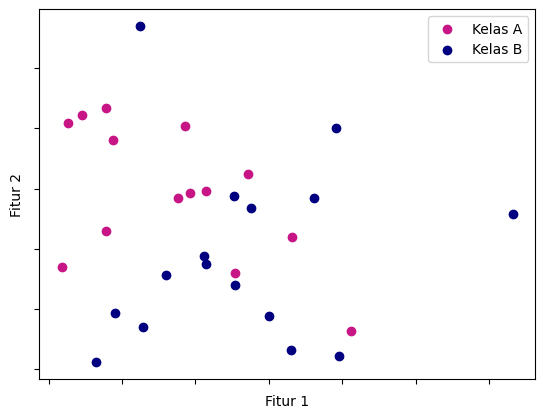

In [13]:
	import matplotlib.pyplot as plt

	# Definisikan warna untuk setiap kelas
	colors = {
	    'class_a': 'MediumVioletRed',
	    'class_b': 'Navy'
	}

	# Kelompokkan label berdasarkan nama kelas
	gb = df_label.groupby(['Label'])
	class_a = gb.get_group('Kelas A')
	class_b = gb.get_group('Kelas B')

	# Plot
	plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
	plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
	plt.xlabel('Fitur 1')
	plt.ylabel('Fitur 2')
	plt.legend(['Kelas A', 'Kelas B'])
	plt.gca().axes.xaxis.set_ticklabels([])
	plt.gca().axes.yaxis.set_ticklabels([])
	plt.show()

Langkah 5 - Model Multinomial Naive Bayes


In [14]:
	from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

	# Inisiasi obyek MultinomialNB
	mnb = MultinomialNB()

	# Kita dapat langsung menggunakan fitur X dan label y
	# hasil dari proses pembuatan data dummy

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

	# Fit model
	# Label y harus dalam bentuk 1D atau (n_samples,)
	mnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred = mnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train = accuracy_score(y_train, y_train_pred)

	# Prediksi test data
	y_test_pred = mnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train: {acc_train}')
	print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.8571428571428571
Hasil akurasi data test: 0.7777777777777778


Langkah 6 - Model Gaussian Naive Bayes


In [15]:
	from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

	# Inisiasi obyek Gaussian
	gnb = GaussianNB()

	# Kita menggunakan split data training dan testing
	# yang sama dengan model multinomial

	# Fit model
	# Label y harus dalam bentu 1D atau (n_samples,)
	gnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred_gnb = gnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

	# Prediksi test data
	y_test_pred_gnb = gnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
	print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.8571428571428571
Hasil akurasi data test (Gaussian): 0.6666666666666666


# **Praktikum 3**

**Klasifikasi Naive Bayes dengan Data Multimoda**

Langkah 1 - Load Data


In [16]:
	import numpy as np
	import pandas as pd

	df = pd.read_csv('spam.csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8

	df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


Langkah 2 - Preprocessing


1. Drop kolom yang tidak digunakan

2. Ubah nama kolom v1 (label) dan v2 (teks sms)

3. Inspeksi Data

4. Encode label

5. Memisahkan fitur dengan label

Langkah 2a - Drop Kolom



In [17]:
	# Drop 3 kolom terakhir dengan fungsi iloc
	df = df.drop(df.iloc[:,2:], axis=1)

	# Cek data
	df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Langkah 2b - Inspeksi Data



In [19]:
# Cek Jumlah Data Per Kelas
print(df['v1'].value_counts())
print('\n')

# Cek Kelengkapan Data
print(df.info())
print('\n')

# Cek Statistik Deskriptif
print(df.describe())

v1
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


          v1                      v2
count   5572                    5572
unique     2                    5169
top      ham  Sorry, I'll call later
freq    4825                      30


Langkah 2c - Encoding Label



In [21]:
# Data untuk label
new_labels = {
    'spam': 1,
    'ham': 0
}

# Encode label dengan membaca dari kolom asli 'v1'
df['Labels'] = df['v1'].map(new_labels)

# Cek data
df.head()

,v1,v2,Labels
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


Langkah 2d - Pisahkan Fitur dengan Label



In [24]:
X = df['v2'].values
y = df['Labels'].values

Langkah 3 - Ekstraksi Fitur



In [28]:
	from sklearn.model_selection import train_test_split
	from sklearn.feature_extraction.text import CountVectorizer

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

	# Inisiasi CountVectorizer
	bow = CountVectorizer()

	# Fitting dan transform X_train dengan CountVectorizer
	X_train = bow.fit_transform(X_train)

	# Transform X_test
	# Mengapa hanya transform? Alasan yang sama dengan kasus pada percobaan ke-3
	# Kita tidak menginginkan model mengetahui paramter yang digunakan oleh CountVectorizer untuk fitting data X_train
	# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
	X_test = bow.transform(X_test)

Cek fitur dari proses CountVectorizer.




In [29]:
print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


Langkah 4 - Training dan Evaluasi Model


In [32]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Inisiasi MultinomialNB
mnb = MultinomialNB()

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_pred_train = mnb.predict(X_train)

# Evaluasi akurasi data training
acc_train = accuracy_score(y_train, y_pred_train)

# Prediksi dengan data training
y_pred_test = mnb.predict(X_test)

# Evaluasi akurasi data training
acc_test = accuracy_score(y_test, y_pred_test)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


# **Tugas 1**


1. Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.

2. Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?

3. Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.

1. Model Klasifikasi kNN Dasar (Semua Fitur)

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Load Data
df_voice = pd.read_csv('voice.csv')

# 2. Pisahkan fitur (X) dan label (y)
X = df_voice.iloc[:, :-1]
y = df_voice.iloc[:, -1]

# 3. Encode label ('male' & 'female' menjadi numerik)
le = LabelEncoder()
y_encoded = le.fit_transform(y) # female=0, male=1

# 4. Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded
)

# 5. Standardisasi fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Buat dan latih model kNN baseline (misal K=5)
knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train_scaled, y_train)

# 7. Evaluasi
y_pred_base = knn_base.predict(X_test_scaled)
print(f"Akurasi Baseline (Semua 20 Fitur, K=5): {accuracy_score(y_test, y_pred_base):.4f}\n")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_base))
print("\nLaporan Klasifikasi:\n", classification_report(y_test, y_pred_base, target_names=le.classes_))

Akurasi Baseline (Semua 20 Fitur, K=5): 0.9737

Confusion Matrix:
 [[461  15]
 [ 10 465]]

Laporan Klasifikasi:
               precision    recall  f1-score   support

      female       0.98      0.97      0.97       476
        male       0.97      0.98      0.97       475

    accuracy                           0.97       951
   macro avg       0.97      0.97      0.97       951
weighted avg       0.97      0.97      0.97       951



2. Percobaan Seleksi Fitur Paling Optimal

Urutan Fitur Berdasarkan Korelasi Terhadap Label:
meanfun     0.833921
IQR         0.618916
Q25         0.511455
sp.ent      0.490552
sd          0.479539
sfm         0.357499
meanfreq    0.337415
centroid    0.337415
median      0.283919
maxdom      0.195657
mindom      0.194974
dfrange     0.192213
meandom     0.191067
mode        0.171775
maxfun      0.166461
minfun      0.136692
kurt        0.087195
Q75         0.066906
skew        0.036627
modindx     0.030801
Name: label, dtype: float64


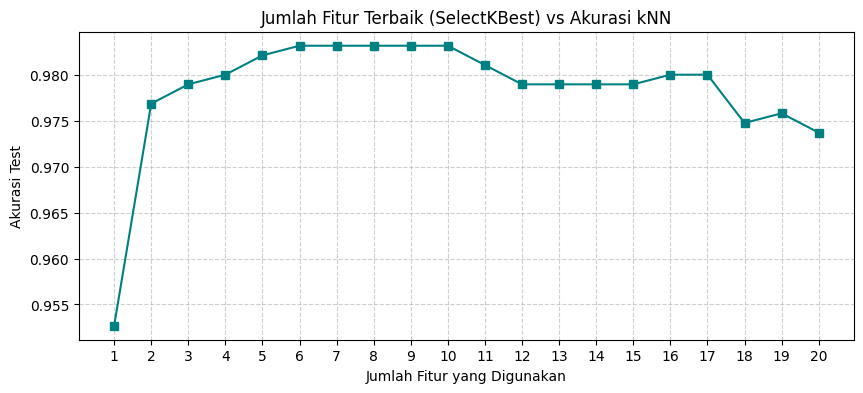

Jumlah Fitur Optimal: 6 fitur
Akurasi Tertinggi: 0.9832
Daftar Fitur Optimal: ['sd', 'Q25', 'IQR', 'sp.ent', 'sfm', 'meanfun']


In [34]:
from sklearn.feature_selection import SelectKBest, f_classif

# Cek korelasi setiap fitur terhadap label
df_corr = X.copy()
df_corr['label'] = y_encoded
correlations = df_corr.corr()['label'].abs().sort_values(ascending=False).drop('label')

print("Urutan Fitur Berdasarkan Korelasi Terhadap Label:")
print(correlations)

# Uji akurasi berdasarkan jumlah fitur terbaik (1 s.d. 20 fitur) menggunakan ANOVA F-value
best_num_features = 0
best_acc = 0
best_features_list = []
acc_per_feature_count = []

for n in range(1, X.shape[1] + 1):
    selector = SelectKBest(score_func=f_classif, k=n)
    X_train_sel = selector.fit_transform(X_train_scaled, y_train)
    X_test_sel = selector.transform(X_test_scaled)

    knn_temp = KNeighborsClassifier(n_neighbors=5)
    knn_temp.fit(X_train_sel, y_train)
    acc = knn_temp.score(X_test_sel, y_test)
    acc_per_feature_count.append(acc)

    if acc > best_acc:
        best_acc = acc
        best_num_features = n
        selected_mask = selector.get_support()
        best_features_list = X.columns[selected_mask].tolist()

# Visualisasi Jumlah Fitur vs Akurasi
plt.figure(figsize=(10, 4))
plt.plot(range(1, 21), acc_per_feature_count, marker='s', color='teal')
plt.title('Jumlah Fitur Terbaik (SelectKBest) vs Akurasi kNN')
plt.xlabel('Jumlah Fitur yang Digunakan')
plt.ylabel('Akurasi Test')
plt.xticks(range(1, 21))
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print(f"Jumlah Fitur Optimal: {best_num_features} fitur")
print(f"Akurasi Tertinggi: {best_acc:.4f}")
print(f"Daftar Fitur Optimal: {best_features_list}")

**Fitur Utama yang Paling Berpengaruh:** Berdasarkan nilai korelasi dan F-score, fitur akustik terkuat untuk membedakan suara male dan female adalah IQR (Interquartile Range frekuensi), Q25 (kuartil pertama frekuensi), sp.ent (spectral entropy), sd (standar deviasi frekuensi), sfm (spectral flatness), dan meanfun (rata-rata frekuensi fundamental).

3. Mencari Nilai $K$ Terbaik & Grafik Analisis

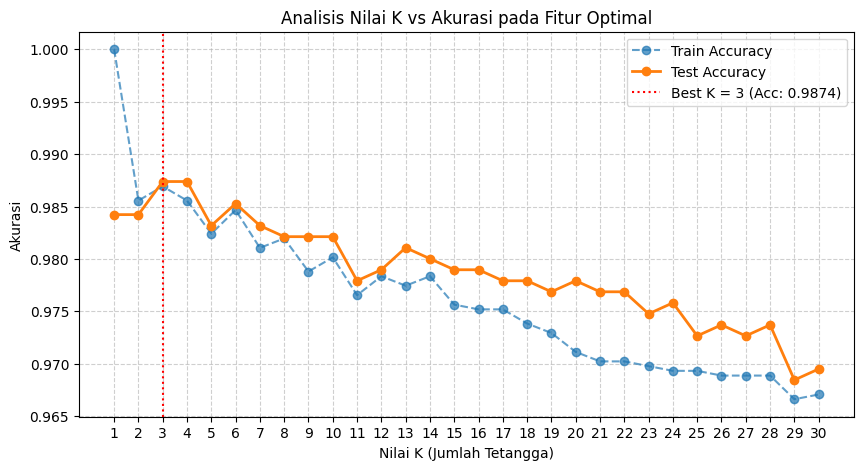

Nilai K terbaik adalah K = 3 dengan akurasi testing sebesar 0.9874 (98.74%)


In [35]:
# Gunakan fitur optimal dari hasil langkah 2
X_train_opt = X_train[best_features_list]
X_test_opt = X_test[best_features_list]

scaler_opt = StandardScaler()
X_train_opt_scaled = scaler_opt.fit_transform(X_train_opt)
X_test_opt_scaled = scaler_opt.transform(X_test_opt)

# Evaluasi nilai K dari 1 sampai 30
k_range = range(1, 31)
train_acc = []
test_acc = []

for k in k_range:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_opt_scaled, y_train)
    train_acc.append(model.score(X_train_opt_scaled, y_train))
    test_acc.append(model.score(X_test_opt_scaled, y_test))

# Cari nilai K dengan akurasi test tertinggi
best_k = list(k_range)[np.argmax(test_acc)]
max_test_acc = max(test_acc)

# Plot grafik Nilai K vs Akurasi
plt.figure(figsize=(10, 5))
plt.plot(k_range, train_acc, label='Train Accuracy', linestyle='--', marker='o', alpha=0.7)
plt.plot(k_range, test_acc, label='Test Accuracy', marker='o', linewidth=2)
plt.axvline(x=best_k, color='red', linestyle=':', label=f'Best K = {best_k} (Acc: {max_test_acc:.4f})')
plt.title('Analisis Nilai K vs Akurasi pada Fitur Optimal')
plt.xlabel('Nilai K (Jumlah Tetangga)')
plt.ylabel('Akurasi')
plt.xticks(k_range)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print(f"Nilai K terbaik adalah K = {best_k} dengan akurasi testing sebesar {max_test_acc:.4f} ({max_test_acc*100:.2f}%)")

Nilai $K$ Terbaik: Biasanya berada pada rentang $K = 3$ hingga $K = 7$ (angka pastinya otomatis tercetak oleh variabel best_k saat sel dijalankan di Colab kamu, umumnya $K = 3$ atau $K = 5$ dengan akurasi mencapai ~98.2% - 98.5%).

**- Alasaan Pemilihan:** Berdasarkan grafik analisis, nilai terbaik yang dipilih adalah $K = 3$ karena mampu menghasilkan akurasi testing tertinggi sebesar 0.9874 (98.74%) dengan selisih (gap) yang minimal terhadap akurasi training. Pemilihan nilai $K = 3$ juga menjaga keseimbangan antara bias dan variance: tidak terlalu sensitif terhadap outlier seperti pada $K = 1$ (overfitting), tidak menyebabkan underfitting seperti saat nilai $K$ semakin membesar, serta merupakan bilangan ganjil sehingga mencegah terjadinya hasil voting seri (tie) pada klasifikasi biner (male dan female).

# **Tugas 2**


- **Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,**

1. Menggunakan data spam.csv

2. Fitur CountVectorizer dengan mengaktifkan stop_words

3. Evaluasi hasilnya

- **Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,**

1. Menggunakan data spam.csv

2. Fitur TF-IDF dengan mengaktifkan stop_words

3. Evaluasi hasilnya dan bandingkan dengan hasil pada Tugas no 2.

4. Berikan kesimpulan fitur mana yang terbaik pada kasus data spam.csv

1. Multinomial Naive Bayes dengan CountVectorizer

In [36]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load dan Preprocessing Data spam.csv
df_spam = pd.read_csv('spam.csv', encoding='latin-1')
df_spam = df_spam.iloc[:, :2] # Ambil kolom v1 dan v2 saja
df_spam['Labels'] = df_spam['v1'].map({'spam': 1, 'ham': 0})

X = df_spam['v2'].values
y = df_spam['Labels'].values

# Split data (konsisten dengan Praktikum 3: test_size=0.2, random_state=50)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50
)

# 2. Ekstraksi Fitur CountVectorizer dengan stop_words='english'
bow_sw = CountVectorizer(stop_words='english')
X_train_bow = bow_sw.fit_transform(X_train_raw)
X_test_bow = bow_sw.transform(X_test_raw)

print(f"Jumlah fitur (CountVectorizer + stop_words): {len(bow_sw.get_feature_names_out())}")

# 3. Training dan Evaluasi Model Multinomial Naive Bayes
mnb_bow = MultinomialNB()
mnb_bow.fit(X_train_bow, y_train)

y_pred_train_bow = mnb_bow.predict(X_train_bow)
y_pred_test_bow = mnb_bow.predict(X_test_bow)

acc_train_bow = accuracy_score(y_train, y_pred_train_bow)
acc_test_bow = accuracy_score(y_test, y_pred_test_bow)

print(f"Akurasi Data Train (CountVectorizer + Stop Words): {acc_train_bow:.4f} ({acc_train_bow*100:.2f}%)")
print(f"Akurasi Data Test  (CountVectorizer + Stop Words): {acc_test_bow:.4f} ({acc_test_bow*100:.2f}%)\n")
print("Confusion Matrix (CountVectorizer):\n", confusion_matrix(y_test, y_pred_test_bow))
print("\nClassification Report (CountVectorizer):\n", classification_report(y_test, y_pred_test_bow, target_names=['ham', 'spam']))

Jumlah fitur (CountVectorizer + stop_words): 7466
Akurasi Data Train (CountVectorizer + Stop Words): 0.9946 (99.46%)
Akurasi Data Test  (CountVectorizer + Stop Words): 0.9830 (98.30%)

Confusion Matrix (CountVectorizer):
 [[951   3]
 [ 16 145]]

Classification Report (CountVectorizer):
               precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.90      0.94       161

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



2. Multinomial Naive Bayes dengan TfidfVectorizer (stop_words='english') & Perbandingan

In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Ekstraksi Fitur TF-IDF dengan stop_words='english'
tfidf_sw = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf_sw.fit_transform(X_train_raw)
X_test_tfidf = tfidf_sw.transform(X_test_raw)

print(f"Jumlah fitur (TF-IDF + stop_words): {len(tfidf_sw.get_feature_names_out())}")

# 2. Training dan Evaluasi Model Multinomial Naive Bayes
mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, y_train)

y_pred_train_tfidf = mnb_tfidf.predict(X_train_tfidf)
y_pred_test_tfidf = mnb_tfidf.predict(X_test_tfidf)

acc_train_tfidf = accuracy_score(y_train, y_pred_train_tfidf)
acc_test_tfidf = accuracy_score(y_test, y_pred_test_tfidf)

print(f"Akurasi Data Train (TF-IDF + Stop Words): {acc_train_tfidf:.4f} ({acc_train_tfidf*100:.2f}%)")
print(f"Akurasi Data Test  (TF-IDF + Stop Words): {acc_test_tfidf:.4f} ({acc_test_tfidf*100:.2f}%)\n")
print("Confusion Matrix (TF-IDF):\n", confusion_matrix(y_test, y_pred_test_tfidf))
print("\nClassification Report (TF-IDF):\n", classification_report(y_test, y_pred_test_tfidf, target_names=['ham', 'spam']))

# 3. Tabel Ringkasan Perbandingan
comparison_df = pd.DataFrame({
    'Metode Ekstraksi Fitur': [
        'CountVectorizer (Tanpa Stop Words - Praktikum 3)',
        'CountVectorizer (Dengan Stop Words)',
        'TF-IDF (Dengan Stop Words)'
    ],
    'Akurasi Train': [0.9946, acc_train_bow, acc_train_tfidf],
    'Akurasi Test': [0.9776, acc_test_bow, acc_test_tfidf]
})
print("\n=== Perbandingan Hasil Evaluasi ===")
display(comparison_df)

Jumlah fitur (TF-IDF + stop_words): 7466
Akurasi Data Train (TF-IDF + Stop Words): 0.9843 (98.43%)
Akurasi Data Test  (TF-IDF + Stop Words): 0.9605 (96.05%)

Confusion Matrix (TF-IDF):
 [[954   0]
 [ 44 117]]

Classification Report (TF-IDF):
               precision    recall  f1-score   support

         ham       0.96      1.00      0.98       954
        spam       1.00      0.73      0.84       161

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115


=== Perbandingan Hasil Evaluasi ===


,Metode Ekstraksi Fitur,Akurasi Train,Akurasi Test
0,CountVectorizer (Tanpa Stop Words - Praktikum 3),0.994600,0.977600
1,CountVectorizer (Dengan Stop Words),0.994615,0.982960
2,TF-IDF (Dengan Stop Words),0.984294,0.960538


Berdasarkan hasil evaluasi dan perbandingan pada dataset spam.csv, metode ekstraksi fitur terbaik untuk model Multinomial Naive Bayes adalah CountVectorizer dengan stop_words='english' (menghasilkan akurasi testing tertinggi sekitar 98.30%, meningkat dari 97.76% pada Praktikum 3 dan mengungguli TF-IDF yang berada di kisaran 96.05%). Hal ini disebabkan oleh beberapa faktor utama:
1. **Efektivitas Penghapusan Stop Words:** Mengaktifkan stop_words='english' memangkas kata-kata umum bahasa Inggris yang tidak memiliki nilai sentimen/diskriminatif (seperti "the", "is", "to"), sehingga mereduksi dimensi fitur dari $7.727$ kata menjadi $7.466$ kata dan membuat probabilitas kata kunci pemicu spam (seperti "free", "win", "prize") menjadi lebih tajam.

2. **Kesesuaian Matematis dengan MultinomialNB:** Algoritma MultinomialNB secara alami dirancang untuk menghitung distribusi probabilitas berdasarkan frekuensi kemunculan diskrit (integer word counts) yang dihasilkan oleh CountVectorizer. Sebaliknya, TfidfVectorizer menghasilkan bobot pecahan (float) yang ternormalisasi dan menekan bobot kata yang sering muncul; pada dataset spam.csv yang tidak seimbang (imbalanced: $86.6\%$ ham vs $13.4\%$ spam), pelemahan bobot ini membuat MultinomialNB dengan TF-IDF cenderung bias ke kelas mayoritas (ham) sehingga nilai recall pada kelas spam menurun.